# Homework 7: Training Without Clean Images
## Name: Jon Knapp
### Date: November 18, 2026
### Class: EE 513 Intro to Image Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Checking my work and my logic
* Checking and assistance with reflections

I used Claude (Anthropic) to write the alignment, training, evaluation and export code and to draft the written answers, which I then reviewed and edited. I checked it by testing the alignment on frames shifted by known sub-pixel amounts before trusting it on the burst, comparing the measured loss gap between the two training methods against the value predicted from the noise variance, repeating training with a second seed to measure how much of any difference is chance, and comparing the ONNX export against PyTorch on the same input. Answers that quote numbers are generated from the notebook's own variables, so they always match the printed output.

**The burst.** Sixteen native (Bayer) RAW DNGs from the main 1× camera of my iPhone 16 Pro Max (6.765 mm f/1.78), shot with ProCamera at ISO 2500 and 1/125 s: a book cover lit by a steady lamp, with the phone braced on a solid support for the burst. This is Project 2 Burst A, the noisiest of my three bursts. Problem 1 prints the settings read from the files, and two facts about them that matter below: how much of the frame is clipped, and how much of the ISO is real sensor gain (above about ISO 430 this phone adds the rest as a `BaselineExposure` tag, which rawpy and this notebook ignore).

**Dry run.** `DEMO_SYNTHETIC = True` runs the notebook on a simulated burst built from my Homework 2 slanted-edge capture. It only tests the code; no number from it is in this submission.

**Project 2.** This is Project 2 Part B and Part C on a small network: the burst average is the denoising ground truth, the alignment and residual-noise estimate carry over as-is, and the ONNX export and timing protocol are the ones Part C asks for.

In [1]:
import os
import platform
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rawpy
import tifffile
import torch
import torch.nn as nn
from IPython.display import Markdown, display
from scipy.ndimage import gaussian_filter

EE513 = Path.cwd().resolve().parent
BURST_DIR = EE513 / "Project 2" / "Project 2 Captures" / "Bursts" / "ISO 2500"   # Project 2 Burst A, my noisiest burst
DEMO_SYNTHETIC = False      # True only to test the code before the burst exists (see above)

# Saturation measured in Project 1 (Color and Accuracy, item 1): the green sites pile up from about
# 3950 DN, so I use 3940 DN, not the WhiteLevel tag (4095 DN).
SAT_DN = 3940.0

TRAIN_FRACTION = 0.70       # train on the left 70% of the frame, score on the right 30%
PATCH, BATCH, STEPS, LR = 64, 16, 800, 1e-3
SEEDS = (513, 2026)         # first and second training seeds (item 11)
NOISE_MULTIPLE = 4.0        # training noise = 4 x the robust single-frame estimate (item 5)
PEAK = 1.0                  # PSNR peak: saturation, since the data run from 0 (black) to 1 (saturation)
CLIP_GUARD = 0.98           # pixels whose average is this close to saturation are left out of the noise estimate (item 4)
# torch keeps its default thread count (one per physical core). Forcing one per logical core (16 on my 8-core
# Ryzen) oversubscribed the cores and made training and the PyTorch timing several times slower.
device = torch.device("cpu")    # every timing below is CPU

### The scene

Frame 1 of the burst, before any processing. Left: rendered in color with rawpy's defaults, only so the scene is recognizable. Right: what this notebook actually works on, one set of green sites from the raw mosaic, scaled so 0 is black and 1 is saturation, with clipped pixels in red and the line where training (left) stops and scoring (right) starts. Both are shown as the sensor stores them; the phone was upright, so the book appears turned on its side.

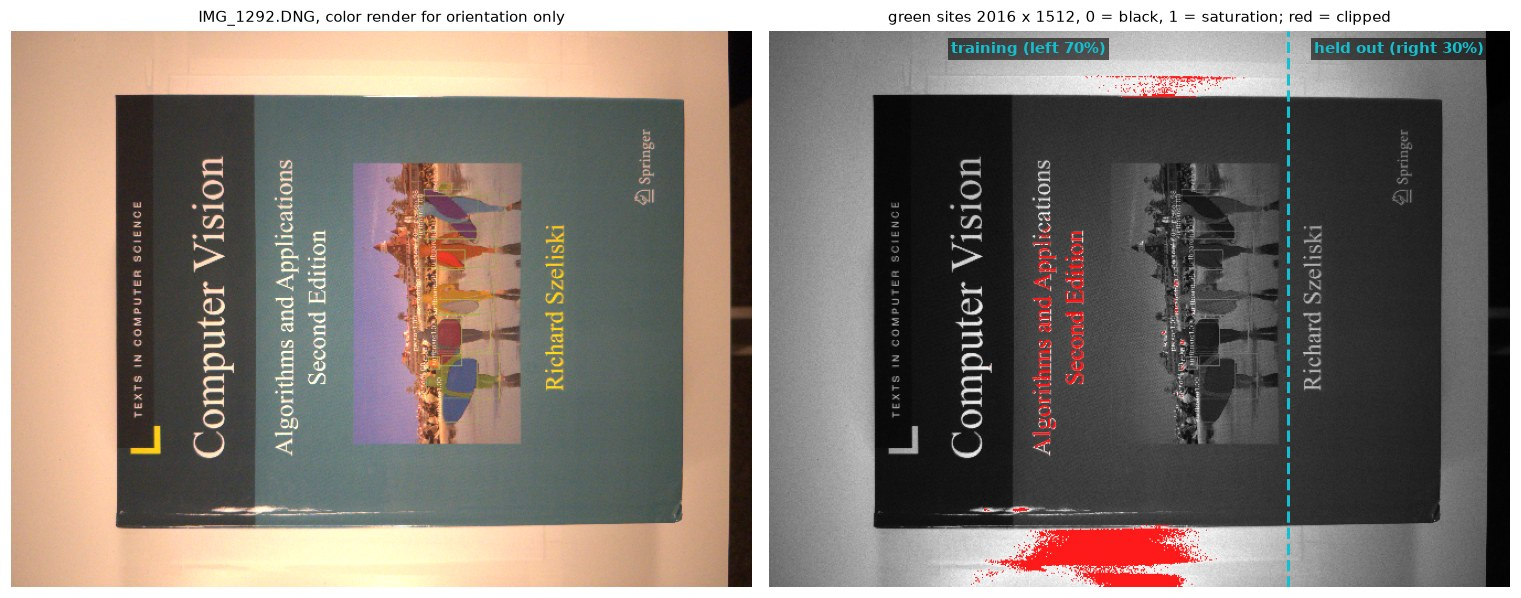

In [2]:
import io
from IPython.display import Image as ShowImage


def show_photo(fig, fname):
    """Save the full-quality PNG next to the notebook, but embed a JPEG: these figures are mostly photograph,
    which PNG compresses poorly, and the notebook stays small enough to submit."""
    fig.savefig(fname, dpi=150, bbox_inches="tight")
    buf = io.BytesIO()
    fig.savefig(buf, format="jpeg", dpi=110, bbox_inches="tight", pil_kwargs={"quality": 88})
    plt.close(fig)
    display(ShowImage(buf.getvalue()))


if not DEMO_SYNTHETIC:
    first = sorted(f for f in BURST_DIR.iterdir() if f.suffix.lower() == ".dng")[0]
    with rawpy.imread(str(first)) as r:
        raw = r.raw_image_visible.astype(np.float64)            # read the mosaic first: postprocess() replaces it
        black0 = float(r.black_level_per_channel[1])
        rgb = r.postprocess(use_camera_wb=True, half_size=True, user_flip=0, output_bps=8)
    g0 = (raw[0::2, 1::2] - black0) / (SAT_DN - black0)       # the same green sites Problem 1 loads
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.4))
    D = 3                                                       # display every 3rd pixel; keeps the file small
    ext = (0, g0.shape[1], g0.shape[0], 0)                      # axes stay in green-site pixel coordinates
    axes[0].imshow(rgb[::D, ::D], extent=ext)
    axes[0].set_title(f"{first.name}, color render for orientation only", fontsize=10)
    axes[1].imshow(np.clip(g0, 0, 1)[::D, ::D], cmap="gray", vmin=0, vmax=1, extent=ext)
    clipped = np.maximum.reduceat(np.maximum.reduceat(g0 >= 1.0, np.arange(0, g0.shape[0], D), 0),
                                  np.arange(0, g0.shape[1], D), 1)        # a block shows red if any pixel in it clipped
    axes[1].imshow(np.ma.masked_where(~clipped, np.ones(clipped.shape)), cmap="autumn", alpha=0.9, extent=ext)
    x_split = TRAIN_FRACTION * g0.shape[1]
    axes[1].axvline(x_split, color="tab:cyan", lw=2, ls="--")
    axes[1].text(x_split / 2, 60, "training (left 70%)", color="tab:cyan", ha="center", fontsize=10, weight="bold",
        bbox=dict(facecolor="black", alpha=0.6, pad=2, edgecolor="none"))
    axes[1].text((x_split + g0.shape[1]) / 2, 60, "held out (right 30%)", color="tab:cyan", ha="center", fontsize=10,
                 weight="bold",
        bbox=dict(facecolor="black", alpha=0.6, pad=2, edgecolor="none"))
    axes[1].set_title(f"green sites {g0.shape[1]} x {g0.shape[0]}, 0 = black, 1 = saturation; red = clipped", fontsize=10)
    for ax in axes:
        ax.axis("off")
    fig.tight_layout(); show_photo(fig, "hw7_scene.png")

## Part 1: A clean image from your burst

### Problem 1: Load the sixteen frames of one burst and take the same green sites from each. Use your noisiest burst.
_Deliverable: The number of frames, and the height and width of one half-size image._

In [3]:
def _lookup(page, name):
    exif = page.tags["ExifTag"].value if "ExifTag" in page.tags else {}
    return exif.get(name, page.tags[name].value if name in page.tags else None)


def capture_info(path):
    """Camera, ISO and exposure from the DNG, for the same-camera, same-ISO check."""
    with tifffile.TiffFile(path) as t:
        p = t.pages[0]
        iso = _lookup(p, "ISOSpeedRatings") or _lookup(p, "PhotographicSensitivity")
        et = _lookup(p, "ExposureTime")
        be = p.tags["BaselineExposure"].value if "BaselineExposure" in p.tags else 0.0
        return {"file": Path(path).name, "lens": _lookup(p, "LensModel"), "software": _lookup(p, "Software"),
                "ISO": int(iso[0] if isinstance(iso, (tuple, list)) else iso),
                "exposure_s": et[0] / et[1] if isinstance(et, (tuple, list)) else float(et),
                "baseline_EV": be[0] / be[1] if isinstance(be, (tuple, list)) else float(be)}


def green_sites(path, sat=SAT_DN):
    """One set of green sites of the raw mosaic, black-subtracted and divided by (saturation - black).
    The site is chosen from the file's CFA pattern: the first green in reading order
    (raw[0::2, 1::2] for my BGGR sensor)."""
    with rawpy.imread(str(path)) as r:
        raw = r.raw_image_visible.astype(np.float64)
        pattern, desc = r.raw_pattern.copy(), r.color_desc.decode()
        gi, gj = next((i, j) for i in range(2) for j in range(2) if desc[pattern[i, j]] == "G")
        black = float(r.black_level_per_channel[pattern[gi, gj]])
    return (raw[gi::2, gj::2] - black) / (sat - black), (gi, gj), black


def synthetic_burst(n=16, seed=7):
    """DRY RUN ONLY. A static scene (one real green plane, lightly smoothed), shifted by a random
    sub-pixel amount per frame, with Poisson-Gaussian noise from my Project 1 model at 12x the gain."""
    src = EE513 / "Project 1" / "Homework 2 Image Captures" / "Slanted Edge" / "IMG_0823.DNG"
    scene, _, _ = green_sites(src)
    scene = np.clip(gaussian_filter(scene, 0.7), 0, 1)
    rng = np.random.default_rng(seed)
    K = 0.246 * 12 / (SAT_DN - 528)            # gain in (fraction of full scale) per electron
    read = 1.694 * 12 / (SAT_DN - 528)         # read noise, fraction of full scale
    frames, true_shifts = [], []
    for k in range(n):
        dx, dy = (0.0, 0.0) if k == 0 else rng.normal(0, 0.6, 2)
        moved = cv2.warpAffine(scene, np.float64([[1, 0, dx], [0, 1, dy]]), scene.shape[::-1],
                               flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REFLECT)
        e = rng.poisson(np.clip(moved, 0, None) / K) * K
        frames.append(e + rng.normal(0, read, e.shape))
        true_shifts.append((dx, dy))
    return frames, np.array(true_shifts)


if DEMO_SYNTHETIC:
    display(Markdown("## ⚠ SYNTHETIC DRY RUN: these numbers are not from my camera and are not for submission."))
    frames, TRUE_SHIFTS = synthetic_burst()
    info = pd.DataFrame([{"file": f"synthetic_{k:02d}", "ISO": "sim", "exposure_s": None} for k in range(len(frames))])
    site, BLACK = (0, 1), 528.0
else:
    files = sorted(f for f in BURST_DIR.iterdir() if f.suffix.lower() == ".dng")
    if len(files) < 16:
        raise FileNotFoundError(f"{len(files)} DNGs in {BURST_DIR}; the burst needs 16.")
    info = pd.DataFrame([capture_info(f) for f in files])
    assert info.lens.nunique() == 1 and info.ISO.nunique() == 1 and info.exposure_s.nunique() == 1, \
        "The burst mixes cameras, ISOs or exposure times:\n" + info.to_string()
    loaded = [green_sites(f) for f in files]
    frames, site, BLACK = [g for g, _, _ in loaded], loaded[0][1], loaded[0][2]
    TRUE_SHIFTS = None

frames = [f.astype(np.float64) for f in frames]
N = len(frames)
DN_SPAN = SAT_DN - BLACK                     # DN per unit of the 0..1 scale
H, W = frames[0].shape
print(f"{N} frames; one half-size green image is {H} x {W} (height x width), green site {site}")
if not DEMO_SYNTHETIC:
    iso, be = info.ISO.iloc[0], info.baseline_EV.iloc[0]
    clip = np.mean([np.mean(f >= 1.0) for f in frames])
    print(f"Camera: {info.lens.iloc[0]} ({info.software.iloc[0]}); ISO {iso}; exposure 1/{1 / info.exposure_s.iloc[0]:.0f} s; "
          f"black level {BLACK:.0f} DN, saturation {SAT_DN:.0f} DN")
    print(f"BaselineExposure {be:+.2f} EV, so the sensor gain is that of about ISO {iso / 2 ** be:.0f}; the rest of the ISO is "
          f"a rendering instruction that this notebook ignores")
    print(f"{clip:.2%} of the green sites are at or above saturation in an average frame")

16 frames; one half-size green image is 1512 x 2016 (height x width), green site (0, 1)
Camera: iPhone 16 Pro Max back camera 6.765mm f/1.78 (ProCamera 27.0.1); ISO 2500; exposure 1/125 s; black level 528 DN, saturation 3940 DN
BaselineExposure +2.53 EV, so the sensor gain is that of about ISO 432; the rest of the ISO is a rendering instruction that this notebook ignores
1.32% of the green sites are at or above saturation in an average frame


### Problem 2: Align every frame to the first. cv2.phaseCorrelate on a Hann-windowed pair gives the shift to a fraction of a pixel. cv2.warpAffine shifts it back. Report the median and the largest shift.
_Deliverable: Those two numbers, in pixels._

In [4]:
def dft_friendly(n):
    """Largest even size <= n that OpenCV's DFT uses without padding."""
    m = n
    while cv2.getOptimalDFTSize(m) != m or m % 2:
        m -= 1
    return m


# cv2.phaseCorrelate pads each image to cv2.getOptimalDFTSize. For my 2016-wide green plane that is 2025,
# an odd size, and the sub-pixel peak then comes back half a pixel off: an image correlated with
# ITSELF reports a 0.5 px shift (printed below). So the shift is estimated on a central crop whose
# size needs no padding.
EH, EW = dft_friendly(H), dft_friendly(W)
EST = (slice((H - EH) // 2, (H - EH) // 2 + EH), slice((W - EW) // 2, (W - EW) // 2 + EW))
HANN = cv2.createHanningWindow((EW, EH), cv2.CV_64F)
_full = cv2.phaseCorrelate(frames[0].copy(), frames[0].copy(), cv2.createHanningWindow((W, H), cv2.CV_64F))[0]
_f0 = frames[0].copy()
print(f"Frame 1 against itself, full {W} x {H} (DFT {cv2.getOptimalDFTSize(W)} x {cv2.getOptimalDFTSize(H)}): "
      f"({_full[0]:+.3f}, {_full[1]:+.3f}) px; on the {EW} x {EH} crop: "
      f"{tuple(round(v, 3) for v in cv2.phaseCorrelate(frames[0][EST].copy(), frames[0][EST].copy(), HANN)[0])} px")


def estimate_shift(ref, img, method="opencv"):
    """(dx, dy) by which `img`'s content is displaced relative to `ref`, in pixels, measured on the
    DFT-friendly central crop. 'opencv' is cv2.phaseCorrelate on the Hann-windowed pair, as the
    assignment specifies; 'skimage' is scikit-image's upsampled phase correlation (1/100 px grid),
    kept as an independent cross-check."""
    # .copy() matters: when no padding is needed, cv2.phaseCorrelate multiplies its inputs by the
    # window IN PLACE, which would silently darken frame 1 (and any array these slices view) each call.
    a, b = ref[EST].copy(), img[EST].copy()
    if method == "opencv":
        (dx, dy), _ = cv2.phaseCorrelate(a, b, HANN)
        return float(dx), float(dy)
    from skimage.registration import phase_cross_correlation
    s, _, _ = phase_cross_correlation(a * HANN, b * HANN, upsample_factor=100)
    return float(-s[1]), float(-s[0])


def shift_image(img, dx, dy):
    """Move the content by (dx, dy) with cubic interpolation."""
    return cv2.warpAffine(img, np.float64([[1, 0, dx], [0, 1, dy]]), (img.shape[1], img.shape[0]),
                          flags=cv2.INTER_CUBIC, borderMode=cv2.BORDER_REFLECT)


# Known-answer test first: displace frame 0 by known sub-pixel amounts and see what comes back.
known = [(0.0, 0.0), (0.25, -0.10), (0.40, 0.70), (-0.60, 0.30), (1.30, -1.70)]
rows = []
for dx, dy in known:
    moved = shift_image(frames[0], dx, dy) + np.random.default_rng(0).normal(0, frames[0].std() * 0.02, frames[0].shape)
    for m in ("opencv", "skimage"):
        ex, ey = estimate_shift(frames[0], moved, m)
        rows.append({"true (dx, dy)": f"({dx:+.2f}, {dy:+.2f})", "method": m, "error dx": ex - dx, "error dy": ey - dy})
selftest = pd.DataFrame(rows)
selftest["|error|"] = np.hypot(selftest["error dx"], selftest["error dy"])
display(selftest.pivot(index="true (dx, dy)", columns="method", values="|error|").style.format("{:.3f}")
        .set_caption("Known-shift test on frame 0: |estimated - true| shift, px"))

Frame 1 against itself, full 2016 x 1512 (DFT 2025 x 1536): (+0.500, -0.000) px; on the 2000 x 1500 crop: (0.0, 0.0) px


method,opencv,skimage
"true (dx, dy)",,
"(+0.00, +0.00)",0.003,0.000
"(+0.25, -0.10)",0.036,0.121
"(+0.40, +0.70)",0.109,0.156
"(+1.30, -1.70)",0.024,0.170
"(-0.60, +0.30)",0.106,0.156


In [5]:
ALIGN_METHOD = "opencv"      # the assignment's method; switch to "skimage" if the test above shows it is more accurate

shifts = {m: np.array([estimate_shift(frames[0], f, m) for f in frames]) for m in ("opencv", "skimage")}
assert np.array_equal(frames[0], _f0), "a frame was modified in place during shift estimation"
aligned = [shift_image(f, -dx, -dy) for f, (dx, dy) in zip(frames, shifts[ALIGN_METHOD])]
mag = np.hypot(*shifts[ALIGN_METHOD][1:].T)                   # frames 2..N relative to frame 1
MARGIN = int(np.ceil(np.abs(shifts[ALIGN_METHOD]).max())) + 4  # crop the edge the warp filled in

shift_table = pd.DataFrame(shifts[ALIGN_METHOD], columns=["dx (px)", "dy (px)"],
                           index=pd.Index(range(1, N + 1), name="frame"))
shift_table["|shift| (px)"] = np.hypot(shift_table["dx (px)"], shift_table["dy (px)"])
shift_table["skimage |shift| (px)"] = np.hypot(*shifts["skimage"].T)
if TRUE_SHIFTS is not None:
    shift_table["true |shift| (synthetic)"] = np.hypot(*TRUE_SHIFTS.T)
display(shift_table.style.format("{:.3f}").set_caption(f"Shift of each frame relative to frame 1 ({ALIGN_METHOD})"))
print(f"Shift relative to the first frame, frames 2-{N} ({ALIGN_METHOD}): "
      f"median {np.median(mag):.3f} px, largest {mag.max():.3f} px; "
      f"the two methods differ by up to {np.abs(shifts['opencv'] - shifts['skimage']).max():.3f} px")

,dx (px),dy (px),|shift| (px),skimage |shift| (px)
frame,,,,
1,0.000,0.000,0.000,0.000
2,-0.087,0.129,0.156,0.082
3,-0.069,0.081,0.106,0.054
4,-0.107,0.123,0.163,0.089
5,0.065,0.084,0.106,0.064
6,0.154,0.114,0.192,0.120
7,0.066,0.083,0.105,0.064
8,0.141,0.160,0.213,0.142
9,0.114,0.088,0.144,0.092


Shift relative to the first frame, frames 2-16 (opencv): median 0.134 px, largest 0.213 px; the two methods differ by up to 0.067 px


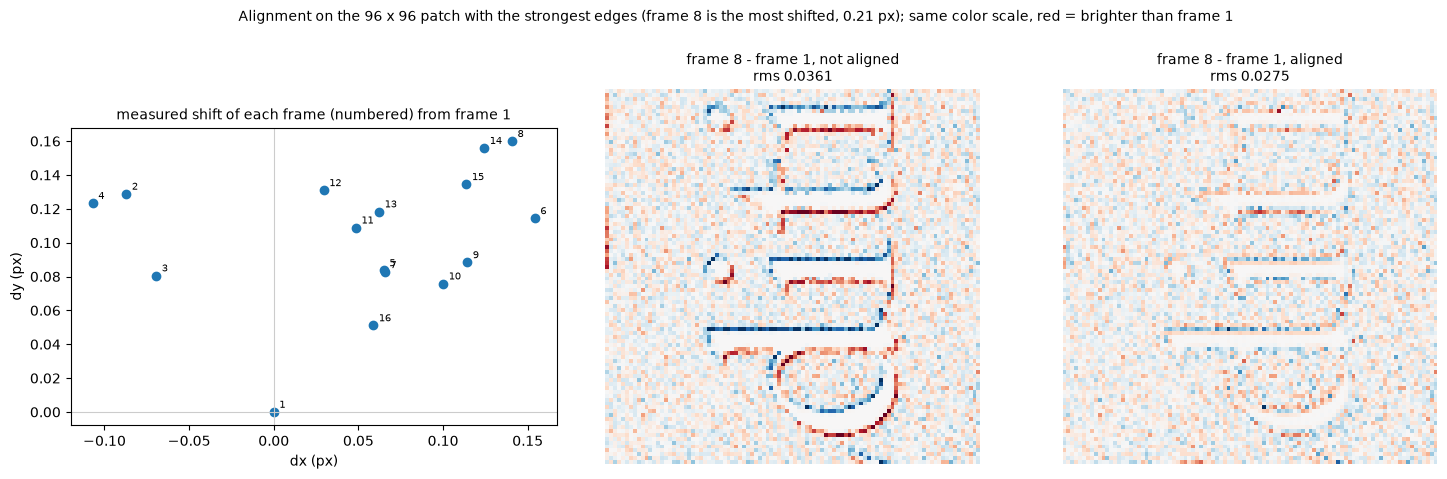

In [6]:
# What alignment does. Left: every frame's measured shift. Middle and right: the most-shifted frame minus frame 1 on the
# patch with the strongest edges, before and after shifting it back. Noise is the same in both; the edge residue is not.
k_big = 1 + int(np.argmax(mag))
grad = gaussian_filter(np.hypot(*np.gradient(gaussian_filter(frames[0], 1))), 30)
gy, gx = np.unravel_index(np.argmax(grad[100:-100, 100:-100]), (H - 200, W - 200))
P2 = (slice(gy + 100 - 48, gy + 100 + 48), slice(gx + 100 - 48, gx + 100 + 48))
before, after = (frames[k_big] - frames[0])[P2], (aligned[k_big] - frames[0])[P2]
lim = np.percentile(np.abs(before), 99.5)

fig, axes = plt.subplots(1, 3, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.1, 1, 1]})
s = shifts[ALIGN_METHOD]
axes[0].scatter(s[:, 0], s[:, 1], c="tab:blue")
for k, (dx, dy) in enumerate(s):
    axes[0].annotate(str(k + 1), (dx, dy), textcoords="offset points", xytext=(4, 3), fontsize=7)
axes[0].axhline(0, color="0.8", lw=0.8); axes[0].axvline(0, color="0.8", lw=0.8)
axes[0].set_xlabel("dx (px)"); axes[0].set_ylabel("dy (px)"); axes[0].set_aspect("equal")
axes[0].set_title("measured shift of each frame (numbered) from frame 1", fontsize=10)
for ax, im, t in ((axes[1], before, f"frame {k_big + 1} - frame 1, not aligned"),
                  (axes[2], after, f"frame {k_big + 1} - frame 1, aligned")):
    ax.imshow(im, cmap="RdBu_r", vmin=-lim, vmax=lim, interpolation="nearest")
    ax.set_title(f"{t}\nrms {im.std():.4f}", fontsize=10); ax.axis("off")
fig.suptitle(f"Alignment on the 96 x 96 patch with the strongest edges (frame {k_big + 1} is the most shifted, "
             f"{mag.max():.2f} px); same color scale, red = brighter than frame 1", fontsize=10, y=1.02)
fig.tight_layout(); fig.savefig("hw7_item2_alignment.png", dpi=150, bbox_inches="tight"); plt.show()

### Problem 3: Average the aligned frames. That's your clean image. Show one frame and the average side by side, same crop, full scale, somewhere with fine detail.
_Deliverable: One figure._

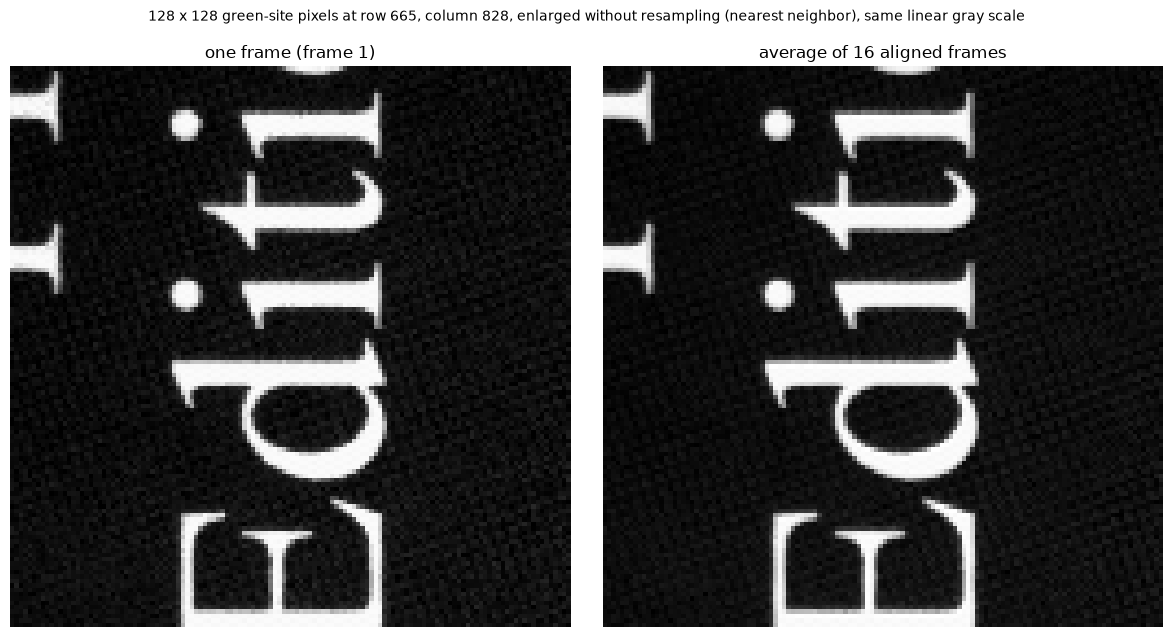

Cropped 5 px from every side after alignment: clean image 1502 x 2006; train columns 0-1403, held-out columns 1404-2005


In [7]:
clean = np.mean(aligned, axis=0)
inner = (slice(MARGIN, H - MARGIN), slice(MARGIN, W - MARGIN))   # every later step works inside this
clean, aligned = clean[inner], [a[inner] for a in aligned]
H, W = clean.shape
SPLIT = int(TRAIN_FRACTION * W)                                    # columns < SPLIT train, >= SPLIT score

# Crop with the most fine detail: highest local variance of the average after removing slow shading.
detail = gaussian_filter((clean - gaussian_filter(clean, 4)) ** 2, 24)
cy, cx = np.unravel_index(np.argmax(detail[64:-64, 64:-64]), (H - 128, W - 128))
cy, cx = cy + 64, cx + 64
C3 = (slice(cy - 64, cy + 64), slice(cx - 64, cx + 64))

lo, hi = np.percentile(clean[C3], [0.5, 99.5])
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2))
for ax, im, t in zip(axes, (aligned[0][C3], clean[C3]), ("one frame (frame 1)", f"average of {N} aligned frames")):
    ax.imshow(im, cmap="gray", vmin=lo, vmax=hi, interpolation="nearest")
    ax.set_title(t); ax.axis("off")
fig.suptitle(f"128 x 128 green-site pixels at row {cy}, column {cx}, enlarged without resampling (nearest neighbor), "
             f"same linear gray scale",
             fontsize=10, y=1.02)
fig.tight_layout(); fig.savefig("hw7_item3_frame_vs_average.png", dpi=150, bbox_inches="tight"); plt.show()
print(f"Cropped {MARGIN} px from every side after alignment: clean image {H} x {W}; train columns 0-{SPLIT - 1}, "
      f"held-out columns {SPLIT}-{W - 1}")

### Problem 4: Estimate the noise in one frame from the difference of two aligned frames, divided by the square root of two. Do it twice. Once as a standard deviation, and once as the median absolute deviation divided by 0.6745.
_Deliverable: The two numbers, and one sentence on what their disagreement tells you about your alignment._

In [8]:
# A clipped pixel reads the same in every frame, so its difference is exactly zero. Leaving clipped pixels in would pull
# both estimates (the MAD most) below the true noise, so pixels whose average is near saturation are left out.
UNCLIPPED = clean < CLIP_GUARD


def noise_estimates(a, b, mask=UNCLIPPED):
    d = (a - b) / np.sqrt(2)
    x = d[mask]
    sd = x.std(ddof=1)
    robust = np.median(np.abs(x - np.median(x))) / 0.6745
    return sd, robust, d


SIGMA_SD, SIGMA_ROBUST, diff01 = noise_estimates(aligned[0], aligned[1])
sd_all, rob_all, _ = noise_estimates(aligned[0], aligned[1], np.ones_like(UNCLIPPED))
# The same pair aligned with the other method, to see whether the disagreement is about alignment.
other = "skimage" if ALIGN_METHOD == "opencv" else "opencv"
f1_other = shift_image(frames[1], -shifts[other][1][0], -shifts[other][1][1])[inner]
sd_o, rob_o, _ = noise_estimates(aligned[0], f1_other)
# And between two frames whose estimated shift is smallest, where interpolation matters least.
k_small = 1 + int(np.argmin(mag))
sd_s, rob_s, _ = noise_estimates(aligned[0], aligned[k_small])

noise_tab = pd.DataFrame({
    "std / sqrt(2)": [SIGMA_SD, sd_o, sd_s, sd_all], "MAD / 0.6745 / sqrt(2)": [SIGMA_ROBUST, rob_o, rob_s, rob_all]},
    index=[f"frames 1 and 2, {ALIGN_METHOD} (used)", f"frames 1 and 2, {other}", f"frames 1 and {k_small + 1} (smallest shift)",
           "frames 1 and 2, clipped pixels left in"])
noise_tab["ratio"] = noise_tab.iloc[:, 0] / noise_tab.iloc[:, 1]
display(noise_tab.style.format("{:.5f}", subset=noise_tab.columns[:2]).format("{:.2f}", subset=["ratio"])
        .set_caption(f"Single-frame noise, fraction of full scale (x {DN_SPAN:.0f} for DN); "
                     f"{1 - UNCLIPPED.mean():.2%} of pixels (near saturation) left out"))

# Where are the large differences? If they sit on edges, the frames are not quite registered.
edges = np.hypot(*np.gradient(gaussian_filter(clean, 1)))
tail = (np.abs(diff01) > 4 * SIGMA_ROBUST) & UNCLIPPED
on_edges = edges[tail].mean() / edges.mean() if tail.any() else float("nan")
# The same two estimates on flat pixels (gradient below the median) within one brightness band (40th-60th percentile):
# no edges there, and shot noise is nearly constant across the band, so any remaining disagreement isn't misregistration.
flat = edges < np.median(edges[UNCLIPPED])
band = (clean > np.quantile(clean, 0.4)) & (clean < np.quantile(clean, 0.6))
sd_flat, rob_flat, _ = noise_estimates(aligned[0], aligned[1], UNCLIPPED & flat & band)
print(f"Flat pixels in one brightness band: std {sd_flat:.5f}, robust {rob_flat:.5f}, ratio {sd_flat / rob_flat:.2f}")
print(f"{tail.sum() / UNCLIPPED.sum():.3%} of pixels lie beyond 4 robust sigma (Gaussian: 0.006%); their mean gradient is "
      f"{on_edges:.1f}x the frame average")

,std / sqrt(2),MAD / 0.6745 / sqrt(2),ratio
"frames 1 and 2, opencv (used)",0.01488,0.01229,1.21
"frames 1 and 2, skimage",0.01511,0.01250,1.21
frames 1 and 16 (smallest shift),0.01432,0.01196,1.20
"frames 1 and 2, clipped pixels left in",0.01491,0.01227,1.22


Flat pixels in one brightness band: std 0.01404, robust 0.01376, ratio 1.02
0.586% of pixels lie beyond 4 robust sigma (Gaussian: 0.006%); their mean gradient is 5.3x the frame average


In [9]:
ratio = SIGMA_SD / SIGMA_ROBUST
ratio_flat = sd_flat / rob_flat
if ratio < 1.2 and ratio_flat < 1.1:
    verdict = ("they agree, so the difference image is close to Gaussian and the frames are registered to well under the "
               "scale of the edges")
elif on_edges > 1.5 and ratio_flat < 1.1:
    verdict = (f"the standard deviation is {ratio:.2f}x the robust estimate because the difference image has a heavy tail, "
               f"and that tail sits on edges: the pixels beyond 4σ have {on_edges:.1f}x the average gradient, and on flat "
               f"pixels of one brightness the two estimates agree (ratio {ratio_flat:.2f}). So the alignment is good but not "
               f"perfect: a residual of up to about a tenth of a pixel, the size of the known-shift test's error, leaves small "
               f"errors along sharp edges, which inflate the standard deviation while the median ignores them. The "
               f"disagreement is modest, so the frames are well registered")
else:
    verdict = (f"the standard deviation is {ratio:.2f}x the robust estimate, but the pixels beyond 4σ do not sit on edges "
               f"(mean gradient {on_edges:.1f}x the average), so the heavy tail is not misregistration; it comes from "
               f"isolated outlier pixels instead")
display(Markdown(
    f"Standard deviation **{SIGMA_SD:.5f}**, robust (MAD / 0.6745) **{SIGMA_ROBUST:.5f}** of full scale "
    f"({SIGMA_SD * DN_SPAN:.1f} and {SIGMA_ROBUST * DN_SPAN:.1f} DN), both measured with the {1 - UNCLIPPED.mean():.2%} of "
    f"pixels near saturation left out, since a clipped pixel is identical in every frame and would pull the estimates down "
    f"(with them left in: {sd_all:.5f} and {rob_all:.5f}). The ratio is {ratio:.2f}: {verdict}. "
    f"Interpolating a frame during alignment also smooths its noise slightly; the frame pair with the smallest shift "
    f"gives {rob_s:.5f}, {100 * (rob_s / SIGMA_ROBUST - 1):+.1f}% from the pair used, so that effect is a few percent at "
    f"most. The robust value is the one I use for the noise level, and the residual "
    f"noise left in the {N}-frame average is about {SIGMA_ROBUST / np.sqrt(N):.5f} ({SIGMA_ROBUST / np.sqrt(N) * DN_SPAN:.1f} DN), "
    f"{np.sqrt(N):.0f}x below one frame."))

Standard deviation **0.01488**, robust (MAD / 0.6745) **0.01229** of full scale (50.8 and 41.9 DN), both measured with the 1.69% of pixels near saturation left out, since a clipped pixel is identical in every frame and would pull the estimates down (with them left in: 0.01491 and 0.01227). The ratio is 1.21: the standard deviation is 1.21x the robust estimate because the difference image has a heavy tail, and that tail sits on edges: the pixels beyond 4σ have 5.3x the average gradient, and on flat pixels of one brightness the two estimates agree (ratio 1.02). So the alignment is good but not perfect: a residual of up to about a tenth of a pixel, the size of the known-shift test's error, leaves small errors along sharp edges, which inflate the standard deviation while the median ignores them. The disagreement is modest, so the frames are well registered. Interpolating a frame during alignment also smooths its noise slightly; the frame pair with the smallest shift gives 0.01196, -2.7% from the pair used, so that effect is a few percent at most. The robust value is the one I use for the noise level, and the residual noise left in the 16-frame average is about 0.00307 (10.5 DN), 4x below one frame.

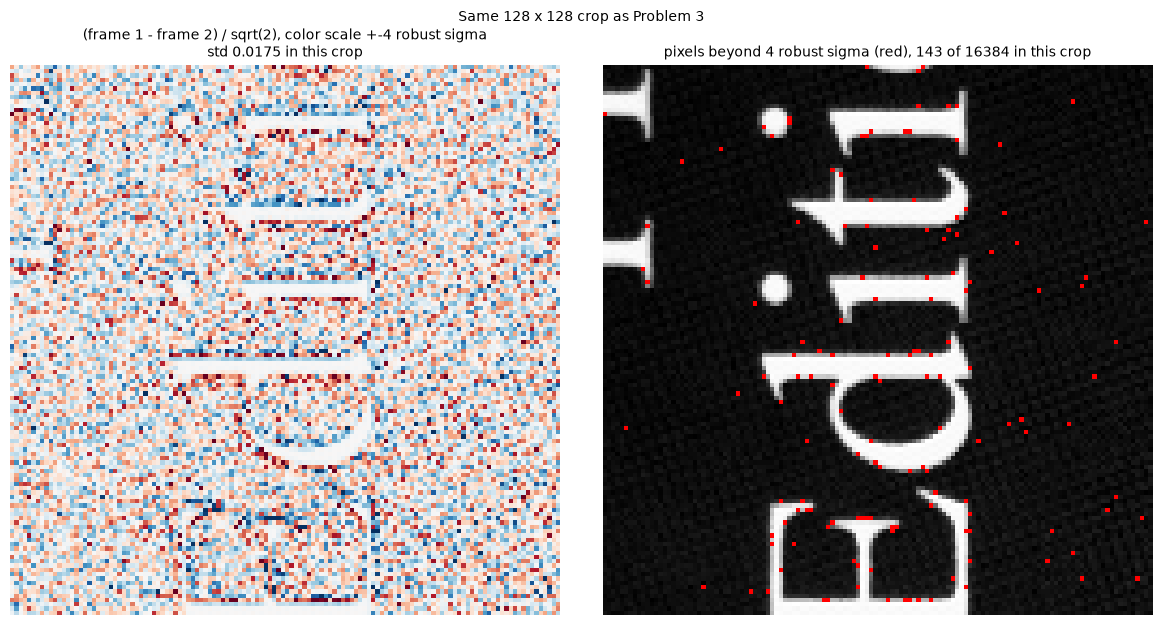

In [10]:
# What item 4 measures, on the Problem 3 crop. Left: the difference of frames 1 and 2 divided by sqrt(2), which is one
# frame's noise. Right: the pixels beyond 4 robust sigma (red) on top of the clean image; most line the letters' edges.
d_crop = diff01[C3]
fig, axes = plt.subplots(1, 2, figsize=(12, 6.2))
axes[0].imshow(d_crop, cmap="RdBu_r", vmin=-4 * SIGMA_ROBUST, vmax=4 * SIGMA_ROBUST, interpolation="nearest")
axes[0].set_title(f"(frame 1 - frame 2) / sqrt(2), color scale +-4 robust sigma\nstd {d_crop.std():.4f} in this crop",
                  fontsize=10)
lo3, hi3 = np.percentile(clean[C3], [0.5, 99.5])
axes[1].imshow(clean[C3], cmap="gray", vmin=lo3, vmax=hi3, interpolation="nearest")
axes[1].imshow(np.ma.masked_where(~tail[C3], np.ones(d_crop.shape)), cmap="autumn", alpha=1.0, interpolation="nearest")
axes[1].set_title(f"pixels beyond 4 robust sigma (red), {tail[C3].sum()} of {tail[C3].size} in this crop", fontsize=10)
for ax in axes:
    ax.axis("off")
fig.suptitle("Same 128 x 128 crop as Problem 3", fontsize=10, y=1.0)
fig.tight_layout(); fig.savefig("hw7_item4_difference.png", dpi=150, bbox_inches="tight"); plt.show()

### Problem 5: Build your training pair. Add two independent draws of Gaussian noise to your clean image, both at four times the robust estimate from item 4. Report the PSNR of one noisy copy against the clean image, and say what peak you used.
_Deliverable: The PSNR and the peak._

In [11]:
def psnr(est, ref, peak=PEAK):
    mse = float(np.mean((np.asarray(est, np.float64) - np.asarray(ref, np.float64)) ** 2))
    return 10 * np.log10(peak ** 2 / mse)


SIGMA_TRAIN = NOISE_MULTIPLE * SIGMA_ROBUST
rng_pair = np.random.default_rng(12345)
noisy1 = clean + rng_pair.normal(0, SIGMA_TRAIN, clean.shape)
noisy2 = clean + rng_pair.normal(0, SIGMA_TRAIN, clean.shape)
PSNR_NOISY = psnr(noisy1, clean)
display(Markdown(
    f"Training noise σ = {NOISE_MULTIPLE:g} × {SIGMA_ROBUST:.5f} = **{SIGMA_TRAIN:.5f}** of full scale. "
    f"PSNR of the first noisy copy against the clean image: **{PSNR_NOISY:.2f} dB**, peak = **{PEAK:g}**, "
    f"which is saturation ({SAT_DN:.0f} DN minus black), because the data were divided by that span. "
    f"No clipping, so the noise stays zero-mean. As a check, a Gaussian of that σ predicts "
    f"{10 * np.log10(PEAK ** 2 / SIGMA_TRAIN ** 2):.2f} dB."))

Training noise σ = 4 × 0.01229 = **0.04915** of full scale. PSNR of the first noisy copy against the clean image: **26.17 dB**, peak = **1**, which is saturation (3940 DN minus black), because the data were divided by that span. No clipping, so the noise stays zero-mean. As a check, a Gaussian of that σ predicts 26.17 dB.

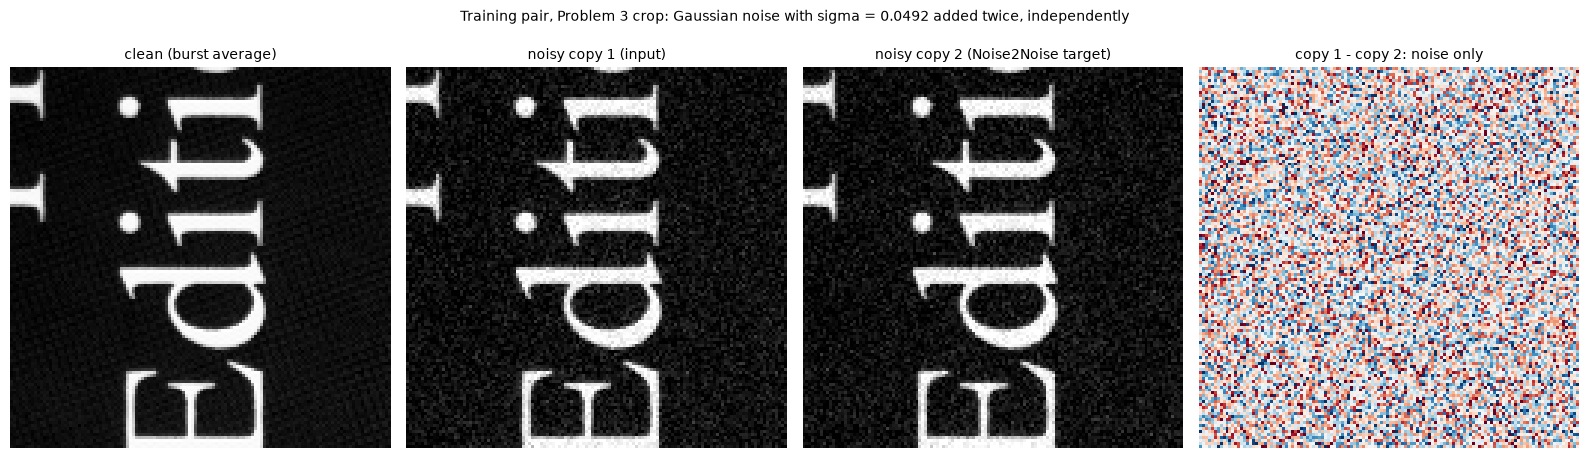

In [12]:
# The training pair on the Problem 3 crop: the same clean image with two independent noise draws. Their difference
# is pure noise (sqrt(2) times one draw), which is why neither copy can predict the other's noise.
lo3, hi3 = np.percentile(clean[C3], [0.5, 99.5])
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
panels = ((clean, "clean (burst average)", lo3, hi3, "gray"), (noisy1, "noisy copy 1 (input)", lo3, hi3, "gray"),
          (noisy2, "noisy copy 2 (Noise2Noise target)", lo3, hi3, "gray"),
          (noisy1 - noisy2, "copy 1 - copy 2: noise only", -3 * SIGMA_TRAIN, 3 * SIGMA_TRAIN, "RdBu_r"))
for ax, (im, t, a, b, cm) in zip(axes, panels):
    ax.imshow(im[C3], cmap=cm, vmin=a, vmax=b, interpolation="nearest"); ax.set_title(t, fontsize=10); ax.axis("off")
fig.suptitle(f"Training pair, Problem 3 crop: Gaussian noise with sigma = {SIGMA_TRAIN:.4f} added twice, independently",
             fontsize=10, y=1.03)
fig.tight_layout(); fig.savefig("hw7_item5_training_pair.png", dpi=150, bbox_inches="tight"); plt.show()

## Part 2: Two ways to train

### Problem 6: Define the network and report how many parameters it has.
_Deliverable: The parameter count._

In [13]:
class DenoiseStack(nn.Module):
    """The lecture 11 stack: six 3x3 convolutions, 32 channels, ReLU between them. It predicts the
    noise, so the output is the input minus what the network produced."""

    def __init__(self, width=32, depth=6):
        super().__init__()
        layers = [nn.Conv2d(1, width, 3, padding=1), nn.ReLU()]
        for _ in range(depth - 2):
            layers += [nn.Conv2d(width, width, 3, padding=1), nn.ReLU()]
        layers.append(nn.Conv2d(width, 1, 3, padding=1))
        self.body = nn.Sequential(*layers)

    def forward(self, noisy):
        return noisy - self.body(noisy)


n_params = sum(p.numel() for p in DenoiseStack().parameters())
by_hand = (1 * 32 * 9 + 32) + 4 * (32 * 32 * 9 + 32) + (32 * 1 * 9 + 1)
assert n_params == by_hand
print(f"Parameters: {n_params:,}  (by hand: 320 + 4 x 9,248 + 289 = {by_hand:,})")

Parameters: 37,601  (by hand: 320 + 4 x 9,248 + 289 = 37,601)


In [14]:
def train(inp, target, seed, steps=STEPS, batch=BATCH, patch=PATCH, lr=LR):
    """Random patch x patch crops from the training columns only. Same seed -> same initial
    weights and same crops, so two runs that differ only in the target are directly comparable."""
    torch.manual_seed(seed)
    rng = np.random.default_rng(seed)
    net = DenoiseStack().to(device)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    X = torch.from_numpy(inp[:, :SPLIT].astype(np.float32))
    Y = torch.from_numpy(target[:, :SPLIT].astype(np.float32))
    losses, t0 = [], time.perf_counter()
    for _ in range(steps):
        ys = rng.integers(0, X.shape[0] - patch + 1, batch)
        xs = rng.integers(0, X.shape[1] - patch + 1, batch)
        xb = torch.stack([X[y:y + patch, x:x + patch] for y, x in zip(ys, xs)])[:, None]
        yb = torch.stack([Y[y:y + patch, x:x + patch] for y, x in zip(ys, xs)])[:, None]
        opt.zero_grad()
        loss = loss_fn(net(xb), yb)
        loss.backward()
        opt.step()
        losses.append(loss.item())
    net.eval()
    return net, np.array(losses), time.perf_counter() - t0


def run(net, img):
    with torch.no_grad():
        return net(torch.from_numpy(img.astype(np.float32))[None, None])[0, 0].numpy().astype(np.float64)


def smooth(x, n=50):
    return np.convolve(x, np.ones(n) / n, mode="valid")


def plot_loss(losses, title, fname, extra=None):
    fig, ax = plt.subplots(figsize=(7.5, 4))
    ax.semilogy(losses, color="0.75", lw=0.8, label="per step")
    ax.semilogy(np.arange(49, len(losses)), smooth(losses), lw=1.8, label="50-step mean")
    for y, lab, ls in (extra or []):
        ax.axhline(y, ls=ls, color="k", lw=1, label=lab)
    ax.set_xlabel(f"step (batch {BATCH} of {PATCH} x {PATCH} patches, Adam lr {LR:g})"); ax.set_ylabel("training MSE")
    ax.set_title(title); ax.legend(fontsize=8)
    fig.tight_layout(); fig.savefig(fname, dpi=150); plt.show()

### Problem 7: Train it the ordinary way. Input the first noisy copy, target the clean image. Plot the loss against step.
_Deliverable: One loss curve._

Supervised training: 800 steps in 269 s


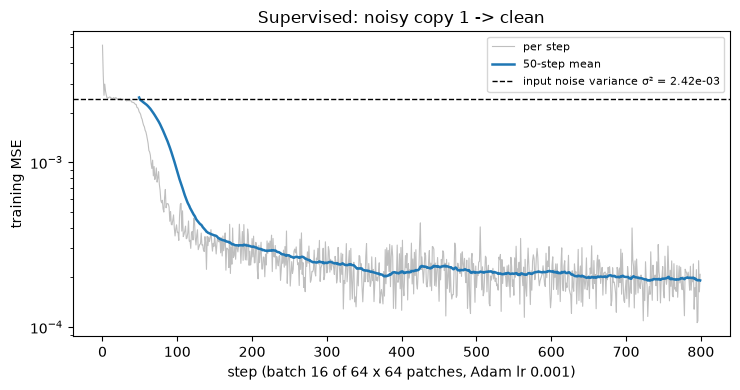

In [15]:
net_sup, loss_sup, t_sup = train(noisy1, clean, SEEDS[0])
print(f"Supervised training: {STEPS} steps in {t_sup:.0f} s")
plot_loss(loss_sup, "Supervised: noisy copy 1 -> clean", "hw7_item7_supervised_loss.png",
          [(SIGMA_TRAIN ** 2, f"input noise variance σ² = {SIGMA_TRAIN ** 2:.2e}", "--")])

### Problem 8: Train a second copy the Noise2Noise way. Same input, but target the second noisy copy. Change nothing else. Plot the loss against step.
_Deliverable: One loss curve._

Noise2Noise training: 800 steps in 281 s


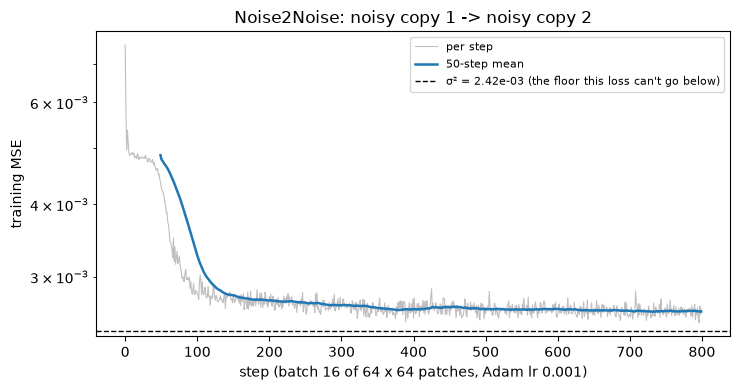

In [16]:
net_n2n, loss_n2n, t_n2n = train(noisy1, noisy2, SEEDS[0])
print(f"Noise2Noise training: {STEPS} steps in {t_n2n:.0f} s")
plot_loss(loss_n2n, "Noise2Noise: noisy copy 1 -> noisy copy 2", "hw7_item8_n2n_loss.png",
          [(SIGMA_TRAIN ** 2, f"σ² = {SIGMA_TRAIN ** 2:.2e} (the floor this loss can't go below)", "--")])

### Problem 9: The two losses settle at different levels. Say why. Give the number the gap should equal, then check it.
_Deliverable: One sentence, the predicted number, and the measured gap._

In [17]:
LAST = 200
gap = loss_n2n[-LAST:].mean() - loss_sup[-LAST:].mean()
gap_se = np.hypot(loss_n2n[-LAST:].std(ddof=1), loss_sup[-LAST:].std(ddof=1)) / np.sqrt(LAST)
display(Markdown(
    f"The Noise2Noise target is the clean image plus a second, independent noise draw that the input carries no "
    f"information about, so no network can predict it and its whole variance, σ², stays in the loss on top of "
    f"whatever error the network makes against the clean image. "
    f"**Predicted gap: σ² = {SIGMA_TRAIN ** 2:.3e}.** "
    f"**Measured gap** (mean of the last {LAST} steps): {gap:.3e} ± {gap_se:.1e} (standard error, treating steps as "
    f"independent), {gap / SIGMA_TRAIN ** 2:.2f} times the prediction."))

The Noise2Noise target is the clean image plus a second, independent noise draw that the input carries no information about, so no network can predict it and its whole variance, σ², stays in the loss on top of whatever error the network makes against the clean image. **Predicted gap: σ² = 2.416e-03.** **Measured gap** (mean of the last 200 steps): 2.421e-03 ± 4.8e-06 (standard error, treating steps as independent), 1.00 times the prediction.

### Problem 10: Report PSNR against the clean image on the held-out right 30 percent, for the noisy input and for each of the two networks.
_Deliverable: Three PSNR values._

,PSNR (dB)
noisy input,26.17
supervised (clean target),40.69
Noise2Noise (noisy target),40.51


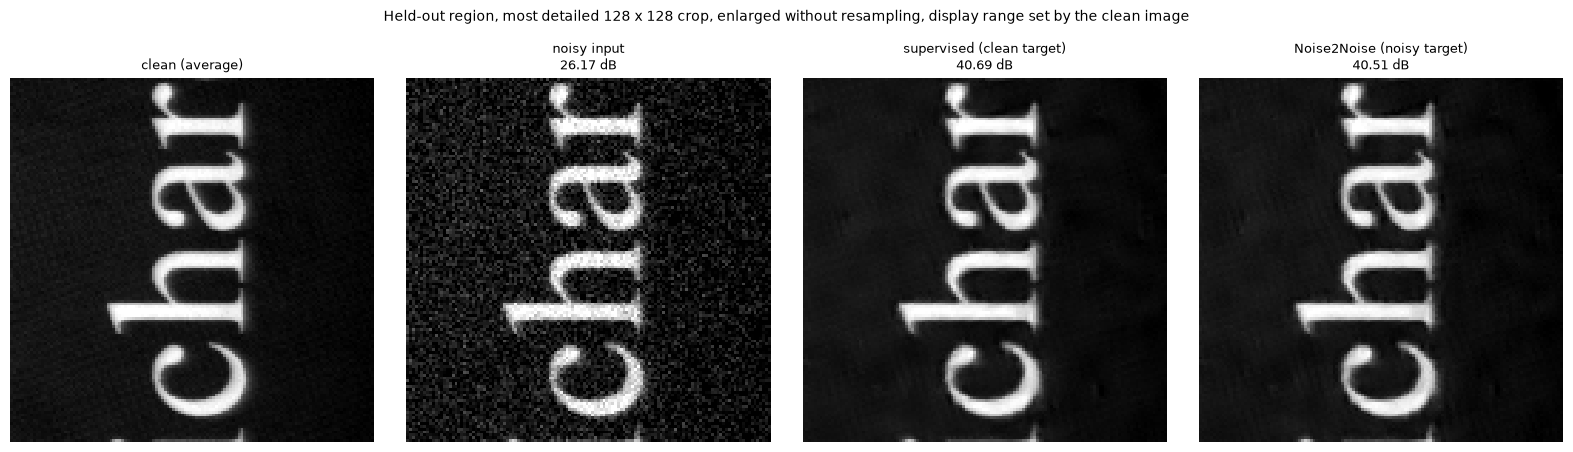

In [18]:
HELD = (slice(None), slice(SPLIT, None))
held_clean, held_noisy = clean[HELD], noisy1[HELD]
out_sup, out_n2n = run(net_sup, held_noisy), run(net_n2n, held_noisy)
P10 = {"noisy input": psnr(held_noisy, held_clean),
       "supervised (clean target)": psnr(out_sup, held_clean),
       "Noise2Noise (noisy target)": psnr(out_n2n, held_clean)}
display(pd.Series(P10, name="PSNR (dB)").to_frame().style.format("{:.2f}").set_caption(
    f"Held-out right {100 - 100 * TRAIN_FRACTION:.0f}% ({held_clean.shape[1]} x {held_clean.shape[0]} px), "
    f"against the burst average; peak {PEAK:g} = saturation"))

dh = detail[:, SPLIT:]                                  # most detailed 128 x 128 crop inside the held-out region
y10, x10 = np.unravel_index(np.argmax(dh[64:-64, 64:-64]), (dh.shape[0] - 128, dh.shape[1] - 128))
C10 = (slice(y10, y10 + 128), slice(x10, x10 + 128))
lo, hi = np.percentile(held_clean[C10], [0.5, 99.5])
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3))
for ax, im, t in zip(axes, (held_clean, held_noisy, out_sup, out_n2n),
                     ("clean (average)", *[f"{k}\n{v:.2f} dB" for k, v in P10.items()])):
    ax.imshow(im[C10], cmap="gray", vmin=lo, vmax=hi, interpolation="nearest"); ax.set_title(t, fontsize=9); ax.axis("off")
fig.suptitle("Held-out region, most detailed 128 x 128 crop, enlarged without resampling, display range set by the "
             "clean image", fontsize=10, y=1.04)
fig.tight_layout(); fig.savefig("hw7_item10_heldout.png", dpi=150, bbox_inches="tight"); plt.show()

## Part 3: Checking the number

### Problem 11: Train the Noise2Noise network again from a different random seed. Change nothing else. Score it the same way, then compare the gap between the two seeds with the gap you found in item 10.
_Deliverable: The second score, and one sentence on which difference is larger and what that lets you claim._

In [19]:
net_n2n_b, loss_n2n_b, _ = train(noisy1, noisy2, SEEDS[1])
P11 = psnr(run(net_n2n_b, held_noisy), held_clean)
seed_gap = abs(P11 - P10["Noise2Noise (noisy target)"])
method_gap = abs(P10["supervised (clean target)"] - P10["Noise2Noise (noisy target)"])
claim = (f"the seed-to-seed difference ({seed_gap:.2f} dB) is larger than the supervised-versus-Noise2Noise difference "
         f"({method_gap:.2f} dB), so the two methods are indistinguishable at this level: I can claim Noise2Noise matched "
         f"the supervised network, not that either one won"
         if seed_gap >= method_gap else
         f"the method difference ({method_gap:.2f} dB) is larger than the seed-to-seed difference ({seed_gap:.2f} dB), but "
         f"with one seed of each that is {method_gap / max(seed_gap, 1e-9):.1f}x a single draw of the spread, so I can claim "
         f"a difference only tentatively; several seeds per method would put an uncertainty on it")
display(Markdown(
    f"Noise2Noise, seed {SEEDS[1]}: **{P11:.2f} dB** (seed {SEEDS[0]}: {P10['Noise2Noise (noisy target)']:.2f} dB). "
    f"Comparing the gaps, {claim}."))

Noise2Noise, seed 2026: **40.48 dB** (seed 513: 40.51 dB). Comparing the gaps, the method difference (0.18 dB) is larger than the seed-to-seed difference (0.03 dB), but with one seed of each that is 5.4x a single draw of the spread, so I can claim a difference only tentatively; several seeds per method would put an uncertainty on it.

### Problem 12: Score the Noise2Noise network on eight random 128 by 128 crops of the held-out region. Then score it on five fresh noise draws of one fixed crop. Report a mean and a standard deviation for each.
_Deliverable: Two mean-and-spread values._

In [20]:
CROP = 128
rng_c = np.random.default_rng(8)
hh, hw = held_clean.shape
corners = list(zip(rng_c.integers(0, hh - CROP + 1, 8), rng_c.integers(0, hw - CROP + 1, 8)))

crop_rows = []
for y, x in corners:
    sl = (slice(y, y + CROP), slice(x, x + CROP))
    crop_rows.append({"crop (row, col)": f"({y}, {x + SPLIT})", "input": psnr(held_noisy[sl], held_clean[sl]),
                      "Noise2Noise": psnr(out_n2n[sl], held_clean[sl])})
crops = pd.DataFrame(crop_rows)

y0, x0 = corners[0]                                      # the fixed crop: the first of the eight
fixed = (slice(y0, y0 + CROP), slice(x0, x0 + CROP))
draw_rows = []
for k in range(5):
    nk = held_clean + np.random.default_rng(9000 + k).normal(0, SIGMA_TRAIN, held_clean.shape)
    ok = run(net_n2n, nk)                                # whole held-out region, so the crop sees real context
    draw_rows.append({"draw": k + 1, "input": psnr(nk[fixed], held_clean[fixed]), "Noise2Noise": psnr(ok[fixed], held_clean[fixed])})
draws = pd.DataFrame(draw_rows)

summary12 = pd.DataFrame({
    "N2N mean (dB)": [crops["Noise2Noise"].mean(), draws["Noise2Noise"].mean()],
    "N2N s.d. (dB)": [crops["Noise2Noise"].std(ddof=1), draws["Noise2Noise"].std(ddof=1)],
    "input mean (dB)": [crops["input"].mean(), draws["input"].mean()],
    "gain s.d. (dB)": [(crops["Noise2Noise"] - crops["input"]).std(ddof=1), (draws["Noise2Noise"] - draws["input"]).std(ddof=1)]},
    index=["8 random crops, one noise draw", "1 fixed crop, 5 fresh noise draws"])
display(summary12.style.format("{:.2f}"))
display(crops.style.format(precision=2).hide(axis="index"))

,N2N mean (dB),N2N s.d. (dB),input mean (dB),gain s.d. (dB)
"8 random crops, one noise draw",40.94,1.47,26.18,1.48
"1 fixed crop, 5 fresh noise draws",41.26,0.21,26.20,0.22


"crop (row, col)",input,Noise2Noise
"(989, 1707)",26.08,41.14
"(449, 1817)",26.25,40.18
"(322, 1426)",26.14,42.09
"(1357, 1589)",26.16,40.95
"(242, 1676)",26.18,38.26
"(438, 1611)",26.19,39.88
"(883, 1588)",26.22,42.55
"(1084, 1581)",26.21,42.47


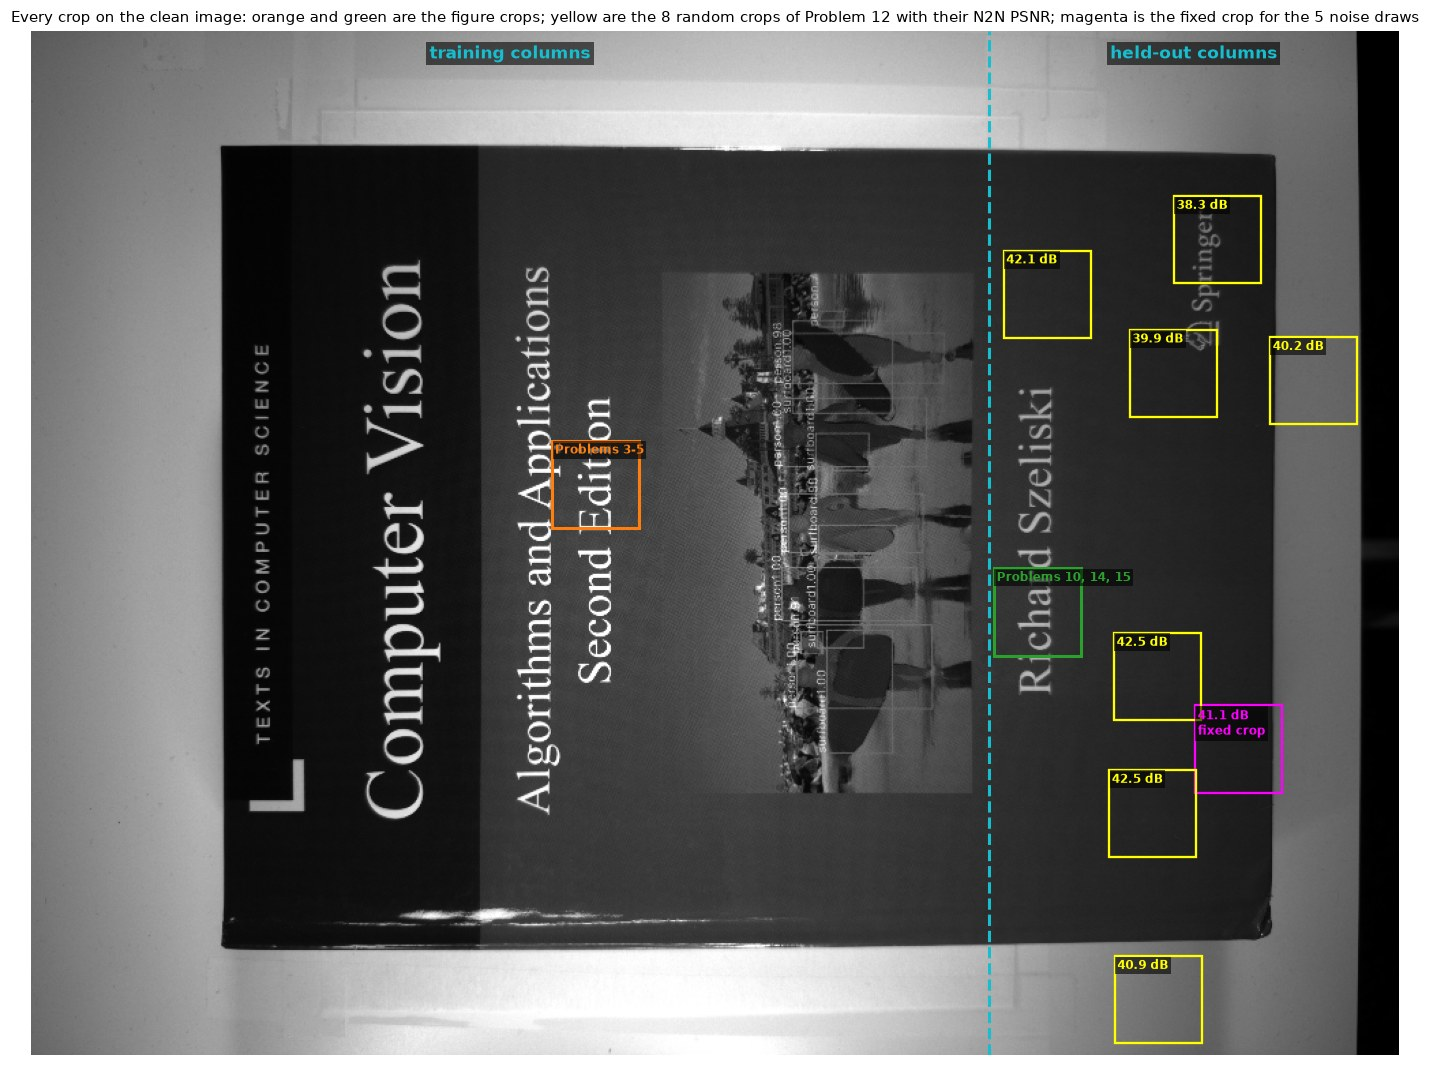

In [21]:
# Where every crop in this notebook comes from, on the clean image. The eight Problem 12 crops are labeled with their
# Noise2Noise PSNR: crops over flat cover score high, crops over lettering score low, which is the spread item 13 is about.
from matplotlib.patches import Rectangle
lo_all, hi_all = np.percentile(clean, [0.5, 99.5])
fig, ax = plt.subplots(figsize=(13, 9.8))
ax.imshow(clean[::2, ::2], cmap="gray", vmin=lo_all, vmax=hi_all, extent=(0, W, H, 0))   # every 2nd pixel, true coordinates
ax.axvline(SPLIT, color="tab:cyan", lw=2, ls="--")
ax.text(SPLIT / 2, 40, "training columns", color="tab:cyan", ha="center", fontsize=11, weight="bold",
        bbox=dict(facecolor="black", alpha=0.6, pad=2, edgecolor="none"))
ax.text((SPLIT + W) / 2, 40, "held-out columns", color="tab:cyan", ha="center", fontsize=11, weight="bold",
        bbox=dict(facecolor="black", alpha=0.6, pad=2, edgecolor="none"))


def box(y, x, color, label, lw=2):
    ax.add_patch(Rectangle((x, y), CROP, CROP, fill=False, edgecolor=color, lw=lw))
    ax.text(x + 4, y + 4, label, color=color, fontsize=8, weight="bold", va="top",
            bbox=dict(facecolor="black", alpha=0.6, pad=1.5, edgecolor="none"))


box(C3[0].start, C3[1].start, "tab:orange", "Problems 3-5")
box(C10[0].start, C10[1].start + SPLIT, "tab:green", "Problems 10, 14, 15")
for k, ((y, x), p) in enumerate(zip(corners, crops["Noise2Noise"])):
    box(y, x + SPLIT, "magenta" if k == 0 else "yellow", f"{p:.1f} dB" + ("\nfixed crop" if k == 0 else ""), lw=1.5)
ax.set_title("Every crop on the clean image: orange and green are the figure crops; yellow are the 8 random crops of "
             "Problem 12 with their N2N PSNR; magenta is the fixed crop for the 5 noise draws", fontsize=10)
ax.axis("off")
fig.tight_layout(); show_photo(fig, "hw7_item12_crop_map.png")

### Problem 13: One of those spreads is much larger. Say which, and what that means if you report a single PSNR from a single crop.
_Deliverable: Two sentences._

In [22]:
s_crop, s_draw = summary12["N2N s.d. (dB)"]
r13 = max(s_crop, s_draw) / max(min(s_crop, s_draw), 1e-9)
if s_crop > s_draw:
    first = (f"The **crop-to-crop** spread is the larger ({s_crop:.2f} dB across crops against {s_draw:.2f} dB across "
             f"noise draws, {r13:.1f}x): PSNR depends more on what is in the crop (flat regions score high, edges and "
             f"texture low) than on the particular noise draw.")
else:
    first = (f"Here the **draw-to-draw** spread is the larger ({s_draw:.2f} dB against {s_crop:.2f} dB across crops, "
             f"{r13:.1f}x), so this held-out region is unusually uniform in content.")
display(Markdown(
    first + f" A single PSNR from a single crop therefore carries an uncertainty of about ±{max(s_crop, s_draw):.1f} dB "
    f"that the number alone doesn't show, so a comparison between methods has to use the same crops (paired), "
    f"average over many of them, and state how they were chosen."))

The **crop-to-crop** spread is the larger (1.47 dB across crops against 0.21 dB across noise draws, 7.2x): PSNR depends more on what is in the crop (flat regions score high, edges and texture low) than on the particular noise draw. A single PSNR from a single crop therefore carries an uncertainty of about ±1.5 dB that the number alone doesn't show, so a comparison between methods has to use the same crops (paired), average over many of them, and state how they were chosen.

### Problem 14: Make a correlated noise field. Smooth Gaussian noise with a 1-pixel Gaussian, then rescale it to the standard deviation you trained at. Add it to the clean image and run the same network. Report the PSNR going in and coming out.
_Deliverable: Two PSNR values._

In [23]:
corr = gaussian_filter(np.random.default_rng(14).normal(0, 1, clean.shape), sigma=1.0)
corr *= SIGMA_TRAIN / corr.std()
noisy_corr = (clean + corr)[HELD]
P14_in, P14_out = psnr(noisy_corr, held_clean), psnr(run(net_n2n, noisy_corr), held_clean)
lag1 = np.corrcoef(corr[:, :-1].ravel(), corr[:, 1:].ravel())[0, 1]
display(Markdown(
    f"Correlated noise at the same σ ({corr.std():.5f}; neighbor correlation {lag1:.2f}, against 0 for the training "
    f"noise): **{P14_in:.2f} dB in, {P14_out:.2f} dB out** ({P14_out - P14_in:+.2f} dB). On white noise at the same σ the "
    f"same network gained {P10['Noise2Noise (noisy target)'] - P10['noisy input']:+.2f} dB: it learned what white noise "
    f"looks like, and smooth blobs of the same variance look to it like image structure, so it removes far less of them "
    f"({P14_out - P14_in:+.2f} dB against {P10['Noise2Noise (noisy target)'] - P10['noisy input']:+.2f} dB)."))

Correlated noise at the same σ (0.04915; neighbor correlation 0.78, against 0 for the training noise): **26.13 dB in, 31.35 dB out** (+5.22 dB). On white noise at the same σ the same network gained +14.34 dB: it learned what white noise looks like, and smooth blobs of the same variance look to it like image structure, so it removes far less of them (+5.22 dB against +14.34 dB).

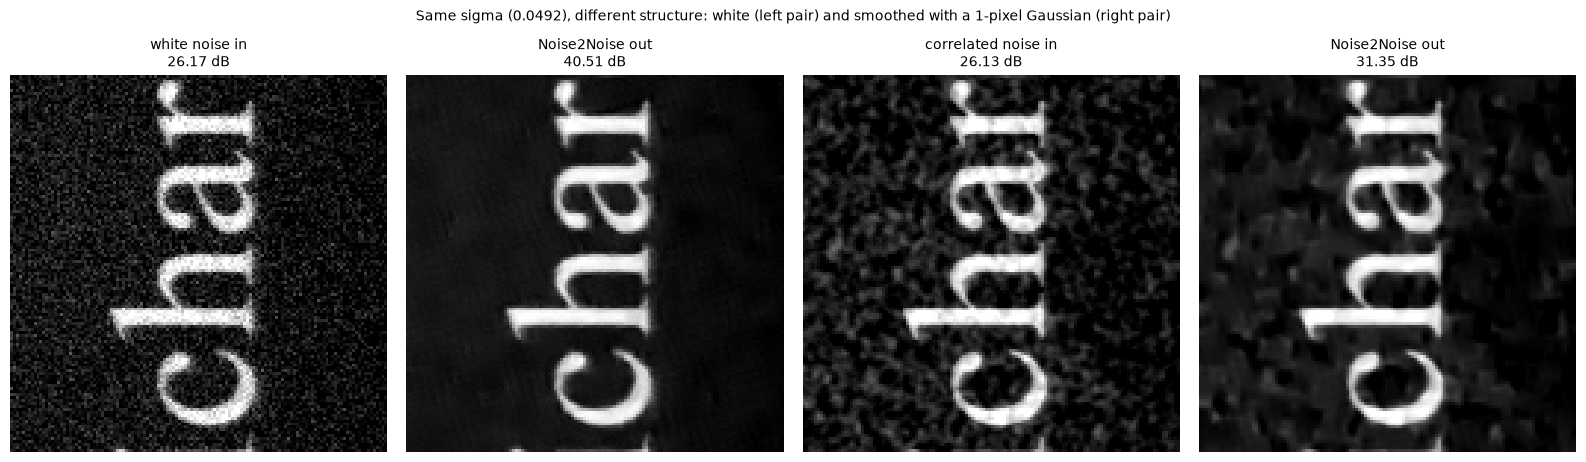

In [24]:
# The same network on white and on correlated noise of the same sigma (Problem 10's crop). It removes the white noise
# and keeps most of the correlated blobs, which look to it like image texture.
out_corr = run(net_n2n, noisy_corr)
lo10, hi10 = np.percentile(held_clean[C10], [0.5, 99.5])
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
for ax, im, t in zip(axes, (held_noisy, out_n2n, noisy_corr, out_corr),
                     (f"white noise in\n{P10['noisy input']:.2f} dB", f"Noise2Noise out\n{P10['Noise2Noise (noisy target)']:.2f} dB",
                      f"correlated noise in\n{P14_in:.2f} dB", f"Noise2Noise out\n{P14_out:.2f} dB")):
    ax.imshow(im[C10], cmap="gray", vmin=lo10, vmax=hi10, interpolation="nearest"); ax.set_title(t, fontsize=10); ax.axis("off")
fig.suptitle(f"Same sigma ({SIGMA_TRAIN:.4f}), different structure: white (left pair) and smoothed with a 1-pixel Gaussian "
             f"(right pair)", fontsize=10, y=1.04)
fig.tight_layout(); fig.savefig("hw7_item14_correlated.png", dpi=150, bbox_inches="tight"); plt.show()

### Problem 15: Run the network on one real raw frame from your burst. Score it against the same clean image. It'll do much less than item 10 suggests.
_Deliverable: The PSNR in and out, and two sentences on the two separate reasons it does worse._

In [25]:
REAL = 0      # frame 1 of the burst: the alignment reference, so it is never interpolated and its noise is the sensor's own
real = aligned[REAL][HELD]
P15_in, P15_out = psnr(real, held_clean), psnr(run(net_n2n, real), held_clean)

# Separate the reasons. (a) Level: white Gaussian noise at the real frame's sigma, through the same network.
white_real = held_clean + np.random.default_rng(15).normal(0, SIGMA_ROBUST, held_clean.shape)
Pw_in, Pw_out = psnr(white_real, held_clean), psnr(run(net_n2n, white_real), held_clean)
# (b) Structure: the real frame's noise against the white-noise assumption.
resid = real - held_clean
real_lag1 = np.corrcoef(resid[:, :-1].ravel(), resid[:, 1:].ravel())[0, 1]
q = np.quantile(held_clean, [0.25, 0.75])
sd_dark, sd_bright = resid[held_clean < q[0]].std(), resid[held_clean > q[1]].std()
# The reference contains 1/N of this frame's noise, and residual noise sigma/sqrt(N) of its own.
ceiling = 10 * np.log10(PEAK ** 2 / (SIGMA_ROBUST ** 2 / N))

display(pd.DataFrame({"PSNR in (dB)": [P15_in, Pw_in, P10["noisy input"]],
                      "PSNR out (dB)": [P15_out, Pw_out, P10["Noise2Noise (noisy target)"]]},
                     index=["real frame", "white Gaussian at the real frame's σ", "item 10: white Gaussian at 4σ (trained)"])
        .assign(**{"change (dB)": lambda d: d.iloc[:, 1] - d.iloc[:, 0]}).style.format("{:.2f}"))
print(f"Real-frame noise: neighbor correlation {real_lag1:.2f}; s.d. {sd_dark:.5f} in the darkest quarter vs "
      f"{sd_bright:.5f} in the brightest ({sd_bright / sd_dark:.2f}x). Measurable ceiling against this reference ≈ {ceiling:.1f} dB")

,PSNR in (dB),PSNR out (dB),change (dB)
real frame,38.22,43.82,5.60
white Gaussian at the real frame's σ,38.21,44.27,6.06
item 10: white Gaussian at 4σ (trained),26.17,40.51,14.34


Real-frame noise: neighbor correlation -0.00; s.d. 0.00719 in the darkest quarter vs 0.01671 in the brightest (2.33x). Measurable ceiling against this reference ≈ 50.3 dB


In [26]:
struct_cost = (Pw_out - Pw_in) - (P15_out - P15_in)          # extra loss from the noise's structure alone
gain10 = P10["Noise2Noise (noisy target)"] - P10["noisy input"]
kind = (f"that costs another {struct_cost:.2f} dB against white noise at the same overall level" if struct_cost > 0.1 else
        f"against white noise at the same overall level that costs little here ({struct_cost:+.2f} dB)")
corr_note = (f"Spatial correlation is not part of it here: I used the alignment reference, which is never interpolated, and "
             f"its noise is white (neighbor correlation {real_lag1:.2f}); an interpolated frame would add correlation, "
             f"which item 14 showed costs much more. " if abs(real_lag1) < 0.05 else
             f"Its noise is also spatially correlated (neighbor correlation {real_lag1:.2f}), which item 14 showed hurts. ")
display(Markdown(
    f"Real frame: **{P15_in:.2f} dB in, {P15_out:.2f} dB out** ({P15_out - P15_in:+.2f} dB, against {gain10:+.2f} dB in "
    f"item 10). First, the level is wrong: the network was trained at {NOISE_MULTIPLE:g}× this frame's noise, and even on "
    f"white Gaussian noise at the real level it gains only {Pw_out - Pw_in:+.2f} dB, because there is a sixteenth of the "
    f"noise power to remove while the smoothing it learned for noise four times stronger also erases real detail, which "
    f"now costs relatively more. Second, the noise is the wrong kind: real noise grows with the signal "
    f"({sd_bright / sd_dark:.1f}x from the darkest to the brightest quarter, shot noise) where the training noise was the "
    f"same everywhere, so one learned strength over-smooths the dark areas and under-smooths the bright ones; {kind}. "
    + corr_note +
    f"(The reference also holds 1/{N} of this frame's noise and its own residual σ/√{N}, which caps a perfect denoiser "
    f"near {ceiling:.0f} dB, well above {P15_out:.1f} dB, so the reference is not what limits this result.)"))

Real frame: **38.22 dB in, 43.82 dB out** (+5.60 dB, against +14.34 dB in item 10). First, the level is wrong: the network was trained at 4× this frame's noise, and even on white Gaussian noise at the real level it gains only +6.06 dB, because there is a sixteenth of the noise power to remove while the smoothing it learned for noise four times stronger also erases real detail, which now costs relatively more. Second, the noise is the wrong kind: real noise grows with the signal (2.3x from the darkest to the brightest quarter, shot noise) where the training noise was the same everywhere, so one learned strength over-smooths the dark areas and under-smooths the bright ones; that costs another 0.45 dB against white noise at the same overall level. Spatial correlation is not part of it here: I used the alignment reference, which is never interpolated, and its noise is white (neighbor correlation -0.00); an interpolated frame would add correlation, which item 14 showed costs much more. (The reference also holds 1/16 of this frame's noise and its own residual σ/√16, which caps a perfect denoiser near 50 dB, well above 43.8 dB, so the reference is not what limits this result.)

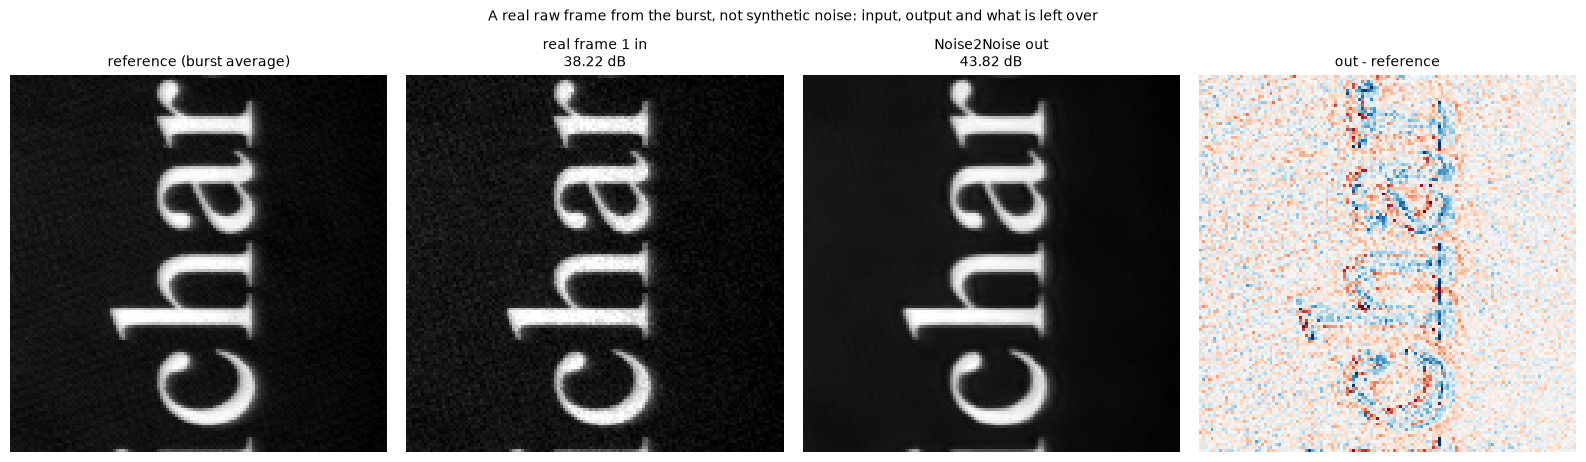

In [27]:
# The real frame through the network (Problem 10's crop). The background noise is gone, and what is left over sits on
# the letters' edges: trained at 4x this frame's noise level, the network smooths real detail along with the noise.
out_real = run(net_n2n, real)
fig, axes = plt.subplots(1, 4, figsize=(16, 4.4))
panels = ((held_clean, "reference (burst average)", lo10, hi10, "gray"), (real, f"real frame 1 in\n{P15_in:.2f} dB", lo10, hi10, "gray"),
          (out_real, f"Noise2Noise out\n{P15_out:.2f} dB", lo10, hi10, "gray"),
          (out_real - held_clean, "out - reference", -4 * SIGMA_ROBUST, 4 * SIGMA_ROBUST, "RdBu_r"))
for ax, (im, t, a, b, cm) in zip(axes, panels):
    ax.imshow(im[C10], cmap=cm, vmin=a, vmax=b, interpolation="nearest"); ax.set_title(t, fontsize=10); ax.axis("off")
fig.suptitle("A real raw frame from the burst, not synthetic noise: input, output and what is left over", fontsize=10, y=1.04)
fig.tight_layout(); fig.savefig("hw7_item15_real_frame.png", dpi=150, bbox_inches="tight"); plt.show()

## Part 4: ONNX and timing

### Problem 16: Export the Noise2Noise network to ONNX and load it with onnxruntime. Run the same input through it and through PyTorch. Report the largest absolute difference.
_Deliverable: That difference, and the number you think it should be compared against._

In [28]:
import onnxruntime as ort

ONNX_PATH = Path("hw7_noise2noise.onnx")
net_n2n.eval()
example = torch.from_numpy(noisy1[:PATCH, :PATCH].astype(np.float32))[None, None]
dyn = torch.export.Dim.DYNAMIC
torch.onnx.export(net_n2n, (example,), str(ONNX_PATH), dynamo=True,
                  input_names=["noisy"], output_names=["denoised"],
                  dynamic_shapes={"noisy": {2: dyn, 3: dyn}})       # height and width free
sess = ort.InferenceSession(str(ONNX_PATH), providers=["CPUExecutionProvider"])
inp = sess.get_inputs()[0]
data_file = ONNX_PATH.with_name(ONNX_PATH.name + ".data")          # the exporter may store the weights here
files = [ONNX_PATH] + ([data_file] if data_file.exists() else [])
print(f"Exported {' + '.join(f'{f.name} ({f.stat().st_size / 1024:.0f} kB)' for f in files)}; input '{inp.name}' shape {inp.shape} "
      f"(symbolic height and width); onnxruntime {ort.__version__}")

x_test = held_noisy.astype(np.float32)[None, None]                  # a different size from the export example
onnx_out = sess.run(None, {inp.name: x_test})[0][0, 0]
torch_out = run(net_n2n, held_noisy).astype(np.float32)
d16 = np.abs(onnx_out - torch_out)
eps32 = np.finfo(np.float32).eps
scale = np.abs(torch_out).max()
display(Markdown(
    f"On the {x_test.shape[3]} × {x_test.shape[2]} held-out region (not the {PATCH} × {PATCH} export size): largest "
    f"|ONNX − PyTorch| = **{d16.max():.2e}**. The comparison is float32 rounding at the size of the output: eps × "
    f"max|output| = {eps32:.2e} × {scale:.3f} = {eps32 * scale:.2e}, and each output sums about "
    f"{9 * 32 * 5 + 9:,} products through six layers in a different order, so a few to a few tens of eps is "
    f"agreement; {d16.max() / (eps32 * scale):.1f} eps here. A wrong export (a missing layer, a transposed kernel) would "
    f"differ by the size of the noise, about {SIGMA_TRAIN:.3f}."))

[torch.onnx] Obtain model graph for `DenoiseStack([...]` with `torch.export.export(..., strict=False)`...
[torch.onnx] Obtain model graph for `DenoiseStack([...]` with `torch.export.export(..., strict=False)`... ✅
[torch.onnx] Run decompositions...
[torch.onnx] Run decompositions... ✅
[torch.onnx] Translate the graph into ONNX...
[torch.onnx] Translate the graph into ONNX... ✅
[torch.onnx] Optimize the ONNX graph...
[torch.onnx] Optimize the ONNX graph... ✅
Exported hw7_noise2noise.onnx (18 kB) + hw7_noise2noise.onnx.data (146 kB); input 'noisy' shape [1, 1, 's69', 's74'] (symbolic height and width); onnxruntime 1.31.1


On the 602 × 1502 held-out region (not the 64 × 64 export size): largest |ONNX − PyTorch| = **1.79e-07**. The comparison is float32 rounding at the size of the output: eps × max|output| = 1.19e-07 × 0.841 = 1.00e-07, and each output sums about 1,449 products through six layers in a different order, so a few to a few tens of eps is agreement; 1.8 eps here. A wrong export (a missing layer, a transposed kernel) would differ by the size of the noise, about 0.049.

### Problem 17: Time one forward pass at 512 by 512 through onnxruntime. Ten runs, after one warm-up run you throw away. Report the mean and the standard deviation. Say what hardware and what image size they belong to.
_Deliverable: The timing with its spread, the size, and the hardware._

In [29]:
def cpu_name():
    try:
        if platform.system() == "Windows":
            import winreg
            k = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
            return winreg.QueryValueEx(k, "ProcessorNameString")[0].strip()
        if platform.system() == "Linux":
            for line in open("/proc/cpuinfo"):
                if line.startswith("model name"):
                    return line.split(":", 1)[1].strip()
    except Exception:
        pass
    return platform.processor() or platform.machine()


S = 512
x512 = held_noisy[:S, :S].astype(np.float32)[None, None]
assert x512.shape[2:] == (S, S), f"held-out region is smaller than {S} x {S}: {held_noisy.shape}"


def time_it(fn, runs=10):
    fn()                                                   # warm-up, discarded
    t = []
    for _ in range(runs):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return 1e3 * np.array(t)


# PyTorch first: onnxruntime's worker threads keep spinning briefly after each run and would compete with it.
xt512 = torch.from_numpy(x512)
with torch.no_grad():
    t_torch = time_it(lambda: net_n2n(xt512))
t_onnx = time_it(lambda: sess.run(None, {inp.name: x512}))
HW = (f"{cpu_name()}, {os.cpu_count()} logical cores, {platform.system()} {platform.release()}; "
      f"onnxruntime {ort.__version__} CPUExecutionProvider, torch {torch.__version__} ({torch.get_num_threads()} threads)")
med = np.median(t_onnx)
slow = np.flatnonzero(t_onnx > 1.5 * med)
spread = (f" The median is {med:.1f} ms. The spread comes from run{'s' if len(slow) > 1 else ''} "
          f"{', '.join(str(k + 1) for k in slow)} ({', '.join(f'{t_onnx[k]:.0f}' for k in slow)} ms), more than 1.5x the "
          f"median; the protocol's single warm-up run was not always enough for the CPU's clock and thread pool to settle."
          if len(slow) else f" The median is {med:.1f} ms, and no run is far from it.")
display(Markdown(
    f"**{t_onnx.mean():.1f} ± {t_onnx.std(ddof=1):.1f} ms** per forward pass (mean ± s.d. of 10 runs after one discarded "
    f"warm-up) through onnxruntime, for one **{S} × {S} single-channel** float32 image on the CPU: {HW}. For comparison, "
    f"PyTorch on the same CPU took {t_torch.mean():.1f} ± {t_torch.std(ddof=1):.1f} ms. Individual runs: "
    f"{', '.join(f'{v:.1f}' for v in t_onnx)} ms." + spread))

**818.2 ± 125.5 ms** per forward pass (mean ± s.d. of 10 runs after one discarded warm-up) through onnxruntime, for one **512 × 512 single-channel** float32 image on the CPU: AMD Ryzen 7 5800X 8-Core Processor, 16 logical cores, Windows 11; onnxruntime 1.31.1 CPUExecutionProvider, torch 2.14.0+cpu (8 threads). For comparison, PyTorch on the same CPU took 1759.1 ± 1081.1 ms. Individual runs: 945.8, 584.4, 883.6, 644.9, 874.7, 871.2, 735.7, 854.6, 967.8, 819.6 ms. The median is 862.9 ms, and no run is far from it.

## Part 5: Reflections
### Problem 18: What did you learn from this assignment?
_Deliverable: A brief written response._

- **A denoiser can be trained without a clean image**

  The Noise2Noise target is noisy, but its noise is independent of the input and has zero mean, so the network that minimizes the loss is the same one that would minimize it against the clean image. The only visible difference is the loss settling σ² higher, which I could predict before training and then measure.

- **The burst average is a real ground truth, with a noise floor I can put a number on**

  Sixteen aligned frames cut the noise by four. The alignment matters: comparing the standard deviation and the robust MAD estimate of the frame difference shows whether the frames are actually registered, and testing the shift estimator on known sub-pixel shifts showed how accurate it is before I trusted it.

- **A PSNR needs its spread before it means anything**

  Crop-to-crop variation was much larger than noise-draw variation, and retraining with another seed moved the score by an amount I had to compare against the method difference before claiming one method beat the other.

- **A learned denoiser is only as general as its training noise**

  Correlated noise at the same variance, or the real frame's weaker, signal-dependent noise, got much less benefit than the white Gaussian noise it was trained on. For Project 2 the training noise has to come from my measured Poisson-Gaussian model, at the levels I'll actually test.

- **The capture has to be checked before the code means anything**

  My first high-ISO burst had a fifth of its pixels clipped, which would have pulled the noise estimate down without any error message, so I reshot it darker and left the remaining clipped pixels out of item 4. I also found that above about ISO 430 this phone adds the extra ISO only as a `BaselineExposure` tag in the DNG, so my "ISO 2500" raw data carries the sensor gain of about ISO 432 and the noise comes from the low light. A burst at ISO 5000 gave the same raw data.

- **ONNX export is checkable against PyTorch to float32 rounding**

  Exporting with free height and width, running a differently sized input, and comparing to PyTorch is a quick end-to-end check of the deployed model, and the timing protocol (warm-up, ten runs, spread, stated hardware) is what Part C needs.

### Problem 19: What questions do you have for me?
_Deliverable: A brief written response._

I have no questions at this time.

### Problem 20: If you used AI tools, say what you used them for and how you verified the output.
_Deliverable: Two sentences, or a statement that you didn't use them._

I used Claude (Anthropic) to write the alignment, training, scoring and ONNX code and to draft these answers, which I reviewed and edited, and the answers that quote numbers are generated from the notebook's own variables so they match the output. I verified it with known-answer tests (the shift estimator against known sub-pixel shifts, the parameter count by hand, the Noise2Noise loss gap against its predicted value σ², the seed-to-seed spread against the method difference, and the ONNX output against PyTorch at a size different from the export), and I checked the burst itself for clipping, motion, brightness drift and sensor gain before using it.